# Fuzzy Logic Based Emergency Communication Priority System
This notebook explains each implementation step.

**Subject:** BE05000461 - Fuzzy Logic & Genetic Programming

**Institute:** L D College of Engineering, Ahmedabad (GTU)

**Deliverable:** Milestone-2 - System Design (Phase 3)

### Step 1: Install Required Libraries

In [1]:
!pip install scikit-fuzzy matplotlib numpy

'pip' is not recognized as an internal or external command,
operable program or batch file.


### Step 2: Import Libraries

In [2]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

### Step 3: Define Input and Output Variables

In [3]:
# Input 1: Emergency Severity (0-10)
severity = ctrl.Antecedent(np.arange(0, 10.01, 0.01), 'severity')

# Input 2: Network Congestion (0-100 %)
congestion = ctrl.Antecedent(np.arange(0, 100.01, 0.01), 'congestion')

# Input 3: Signal Strength / RSSI (-100 to -30 dBm)
rssi = ctrl.Antecedent(np.arange(-100, -29.99, 0.01), 'rssi')

# Output: Call Priority Score (0-100)
priority = ctrl.Consequent(np.arange(0, 100.01, 0.01), 'priority')

### Step 4: Define Membership Functions

#### Emergency Severity

In [4]:
severity['low'] = fuzz.trapmf(severity.universe, [0, 0, 3, 5])
severity['moderate'] = fuzz.trimf(severity.universe, [3, 5, 7])
severity['critical'] = fuzz.trapmf(severity.universe, [5, 7, 10, 10])

c:\Users\aryan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


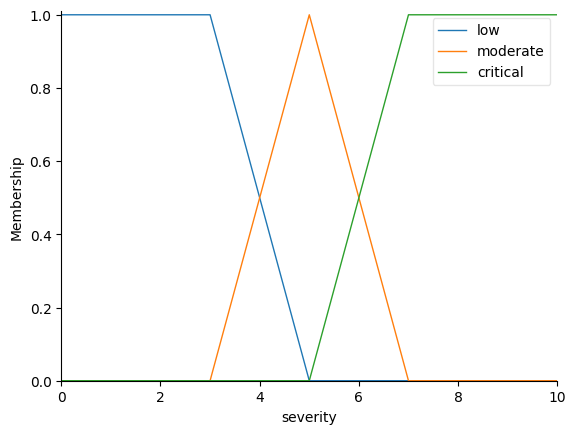

In [5]:
severity.view()

#### Network Congestion

In [6]:
congestion['low'] = fuzz.trapmf(congestion.universe, [0, 0, 30, 50])
congestion['medium'] = fuzz.trimf(congestion.universe, [30, 50, 70])
congestion['high'] = fuzz.trapmf(congestion.universe, [50, 70, 100, 100])

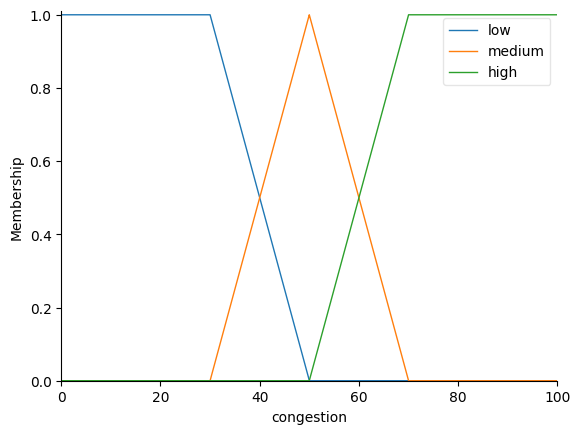

In [7]:
congestion.view()

#### Signal Strength (RSSI)

In [8]:
rssi['weak'] = fuzz.trapmf(rssi.universe, [-100, -100, -85, -70])
rssi['moderate'] = fuzz.trimf(rssi.universe, [-85, -70, -55])
rssi['strong'] = fuzz.trapmf(rssi.universe, [-70, -55, -30, -30])

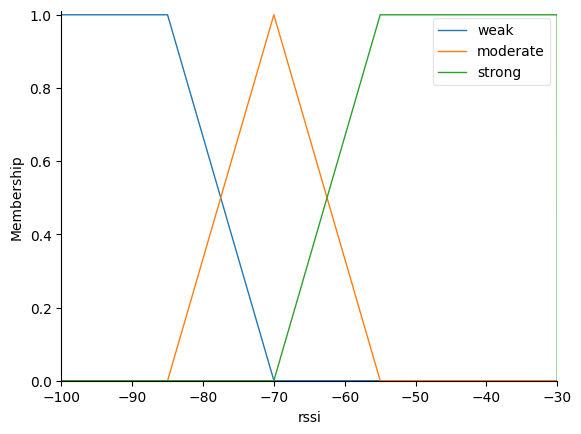

In [9]:
rssi.view()

#### Call Priority Score (Output)

In [10]:
priority['low'] = fuzz.trapmf(priority.universe, [0, 0, 30, 50])
priority['medium'] = fuzz.trimf(priority.universe, [30, 50, 70])
priority['high'] = fuzz.trapmf(priority.universe, [50, 70, 100, 100])

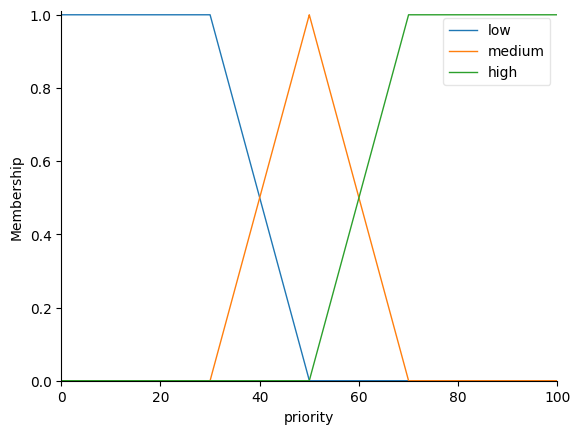

In [11]:
priority.view()

### Step 5: Create Rule Base

In [12]:
# R1: IF Severity=Critical AND Congestion=High THEN Priority=High
rule1 = ctrl.Rule(
    severity['critical'] &
    congestion['high'],
    priority['high']
)

# R2: IF Severity=Low AND Congestion=High THEN Priority=Low
rule2 = ctrl.Rule(
    severity['low'] &
    congestion['high'],
    priority['low']
)

# R3: IF Severity=Critical AND RSSI=Weak THEN Priority=High
rule3 = ctrl.Rule(
    severity['critical'] &
    rssi['weak'],
    priority['high']
)

# R4: IF Severity=Moderate AND Congestion=Medium THEN Priority=Medium
rule4 = ctrl.Rule(
    severity['moderate'] &
    congestion['medium'],
    priority['medium']
)

# R5: IF Severity=Low AND Congestion=Low THEN Priority=Medium
rule5 = ctrl.Rule(
    severity['low'] &
    congestion['low'],
    priority['medium']
)

# R6: IF Severity=Critical AND Congestion=Low THEN Priority=High
rule6 = ctrl.Rule(
    severity['critical'] &
    congestion['low'],
    priority['high']
)

# R7: IF Severity=Moderate AND Congestion=Low AND RSSI=Strong THEN Priority=Medium
rule7 = ctrl.Rule(
    severity['moderate'] &
    congestion['low'] &
    rssi['strong'],
    priority['medium']
)

# R8: IF Severity=Low AND RSSI=Weak THEN Priority=Low
rule8 = ctrl.Rule(
    severity['low'] &
    rssi['weak'],
    priority['low']
)

### Step 6: Create Controller

In [13]:
priority_ctrl = ctrl.ControlSystem([
    rule1,
    rule2,
    rule3,
    rule4,
    rule5,
    rule6,
    rule7,
    rule8
])

system = ctrl.ControlSystemSimulation(priority_ctrl)

### Step 7: Provide Sensor Values

In [14]:
system.input['severity'] = 6.5

system.input['congestion'] = 65

system.input['rssi'] = -80

### Step 8: Run Fuzzy Inference
The default defuzzification method for a Consequent in scikit-fuzzy is centroid.

In [15]:
system.compute()

In [16]:
print(system.output['priority'])

73.6440677966072


### Step 9: Display Result

In [17]:
print("Recommended Call Priority Score:")

print(round(system.output['priority'],2),"/ 100")

Recommended Call Priority Score:
73.64 / 100


### Step 10: Show Defuzzification Graph

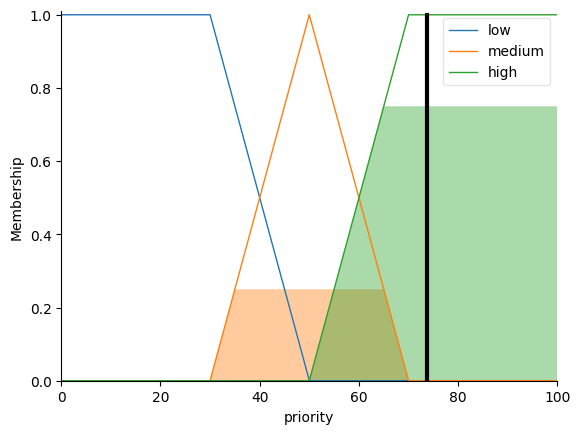

In [18]:
priority.view(sim=system)

plt.show()

### Step-11 Try Different Test Cases
#### Test Case 1: Critical severity, high congestion, weak signal

In [19]:
system.input['severity'] = 9
system.input['congestion'] = 85
system.input['rssi'] = -95
system.compute()

print(system.output['priority'])

79.58333333333323


#### Test Case 2: Low severity, low congestion, strong signal

In [20]:
system.input['severity'] = 1.5
system.input['congestion'] = 15
system.input['rssi'] = -40
system.compute()

print(system.output['priority'])

50.00000000000008


#### Test Case 3: Moderate severity, low congestion, strong signal

In [21]:
system.input['severity'] = 5
system.input['congestion'] = 20
system.input['rssi'] = -35
system.compute()

print(system.output['priority'])

50.00000000000008


### Step-12: Apply different Defuzzification methods and observe the result and compare.
| Method       | Meaning                                          | Typical use                                 |
| ------------ | ------------------------------------------------ | ------------------------------------------- |
| **centroid** | Center of Area / Center of Gravity               | ⭐ Most commonly used                        |
| **bisector** | Divides the aggregated area into two equal areas | Alternative to centroid                     |
| **mom**      | Mean of Maximum                                  | When maximum membership region is important |
| **som**      | Smallest of Maximum                              | Selects the smallest x among maxima         |
| **lom**      | Largest of Maximum                               | Selects the largest x among maxima          |

#### 1. Centroid
It finds the balance point of the aggregated fuzzy output (worked example values: Severity=6.5, Congestion=65%, RSSI=-80 dBm).

In [22]:
priority.defuzzify_method = 'centroid'
system = ctrl.ControlSystemSimulation(priority_ctrl)
system.input['severity'] = 6.5
system.input['congestion'] = 65
system.input['rssi'] = -80
system.compute()
print(round(system.output['priority'],2),"/ 100")

73.64 / 100


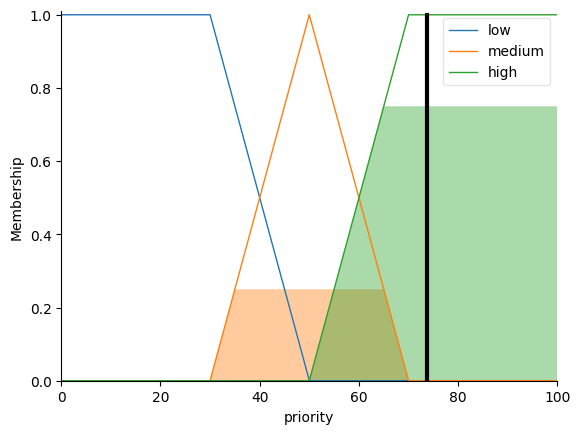

In [23]:
priority.view(sim=system)

plt.show()

#### 2. Bisector

Finds the point that divides the total area under the aggregated membership function into two equal areas.

In [24]:
priority.defuzzify_method = 'bisector'
system = ctrl.ControlSystemSimulation(priority_ctrl)
system.input['severity'] = 6.5
system.input['congestion'] = 65
system.input['rssi'] = -80
system.compute()
print(round(system.output['priority'],2),"/ 100")

75.42 / 100


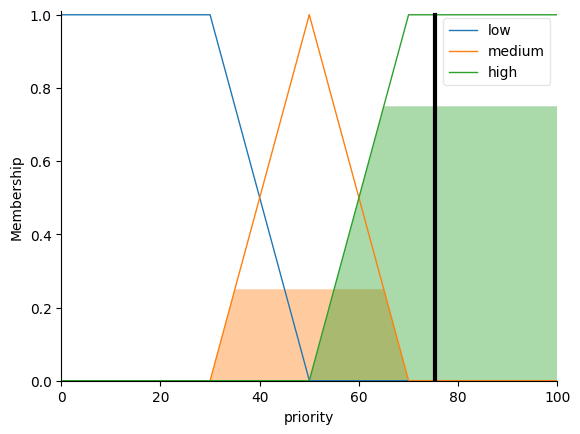

In [25]:
priority.view(sim=system)

plt.show()

#### 3. MOM — Mean of Maximum

Finds all points having the maximum membership value and takes their average.

In [26]:
priority.defuzzify_method = 'mom'
system = ctrl.ControlSystemSimulation(priority_ctrl)
system.input['severity'] = 6.5
system.input['congestion'] = 65
system.input['rssi'] = -80
system.compute()
print(round(system.output['priority'],2),"/ 100")

82.5 / 100


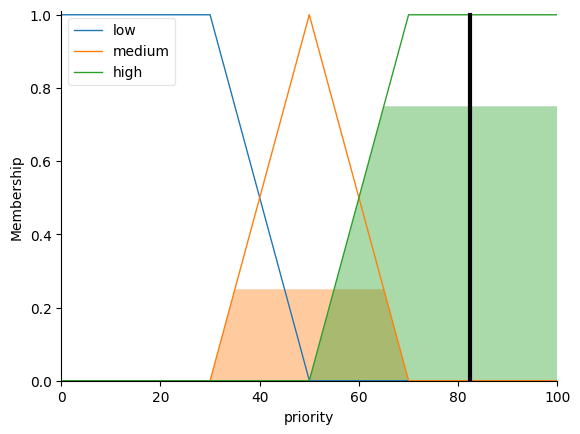

In [27]:
priority.view(sim=system)

plt.show()

#### 4. SOM — Smallest of Maximum

Finds the points having maximum membership and chooses the smallest one.

In [28]:
priority.defuzzify_method = 'som'
system = ctrl.ControlSystemSimulation(priority_ctrl)
system.input['severity'] = 6.5
system.input['congestion'] = 65
system.input['rssi'] = -80
system.compute()
print(round(system.output['priority'],2),"/ 100")

65.0 / 100


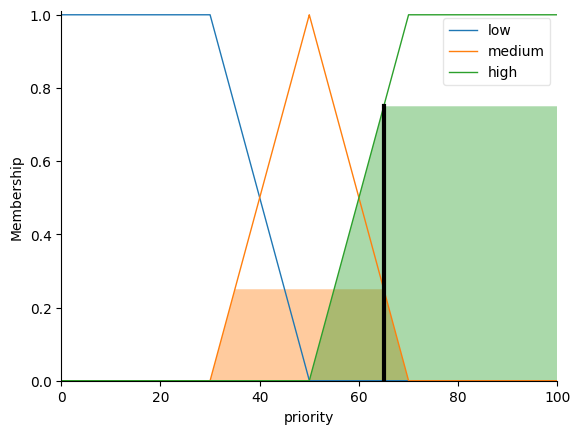

In [29]:
priority.view(sim=system)

plt.show()

#### 5. LOM — Largest of Maximum

Same idea, but chooses the largest maximum point.

In [30]:
priority.defuzzify_method = 'lom'
system = ctrl.ControlSystemSimulation(priority_ctrl)
system.input['severity'] = 6.5
system.input['congestion'] = 65
system.input['rssi'] = -80
system.compute()
print(round(system.output['priority'],2),"/ 100")

100.0 / 100


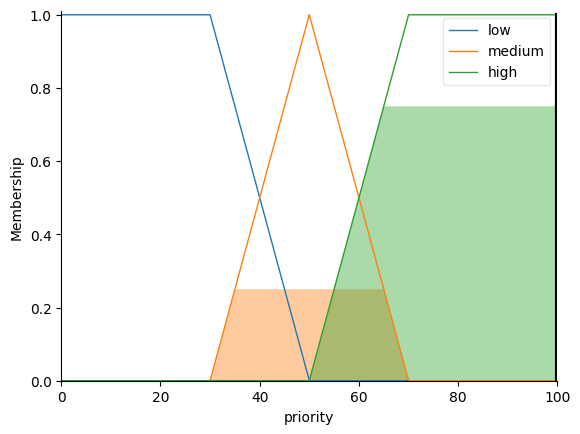

In [31]:
priority.view(sim=system)

plt.show()

Using For Loop

In [32]:
methods = ['centroid', 'bisector', 'mom', 'som', 'lom']

for method in methods:
    priority.defuzzify_method = method

    system = ctrl.ControlSystemSimulation(priority_ctrl)

    system.input['severity'] = 6.5
    system.input['congestion'] = 65
    system.input['rssi'] = -80

    system.compute()

    print(method, system.output['priority'])

centroid 73.6440677966072
bisector 75.41666666666765
mom 82.5
som 65.0
lom 100.0


**Conclusion**: There exist different outputs for different defuzz methods. Centroid is used as the primary method for this project since it best reflects the overall "center of gravity" of every rule that fired, matching the weighted-average approach used in the Phase-2 system design.